In [1]:
# Подключили модули
from sklearn import datasets, linear_model, model_selection, svm

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.markers import MarkerStyle
%matplotlib inline

## Линейная регрессия

In [ ]:
n_samples = 2000
random_state = 123
train_size = 700

In [ ]:
X, y = datasets.make_blobs(n_samples=n_samples, centers = 1, random_state=random_state)
transformation = [[0.6, 0.6], [0.4, 0.8]]
X_aniso = np.dot(X, transformation)

In [ ]:
colors = np.array(['xkcd:bright blue', 'gold'])
plt.scatter(X_aniso[:, 0], X_aniso[:, 1], s=10, color=colors[y-1])

In [ ]:
X_train = X_aniso[:train_size]
X_test = X_aniso[train_size: ]

In [ ]:
lreg = linear_model.LinearRegression().fit(X_train, X_train[:, 1])
lreg.coef_, lreg.intercept_

In [ ]:
X_for_pred = X_test.copy()
X_for_pred.sort(axis = 0)
y_pred = lreg.predict(X_for_pred)
y_pred

In [ ]:
X_for_pred = X_test.copy()
X_for_pred.sort(axis = 0)
y_cust = X_for_pred[:, 0]* lreg.coef_[0] + X_for_pred[:, 1]* lreg.coef_[1] + lreg.intercept_
y_cust

In [ ]:
colors_pred = np.array(['xkcd:salmon', 'xkcd:bright purple'])
plt.scatter(X_test[:, 0], X_test[:, 1], color=colors[y_test-1], s=5)


plt.plot(X_for_pred[:, 0], y_pred, color=colors_pred[0] )

## Логистическая регрессия

In [2]:
iris = datasets.load_iris()

X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.3)

In [3]:
clf = linear_model.LogisticRegression(random_state=0)
model = clf.fit(X_train, y_train)

In [4]:
y_pred = model.predict(X_test)
y_train_pred = model.predict(X_train)

In [5]:
model.score(X_test, y_test)

0.9333333333333333

In [6]:
print(y_pred)

[2 2 0 1 0 2 1 0 2 1 2 2 0 1 2 2 2 2 1 1 2 2 1 0 0 2 2 0 0 2 0 0 1 2 0 1 2
 2 1 1 0 0 1 1 0]


In [7]:
y_test

array([2, 2, 0, 1, 0, 2, 1, 0, 2, 1, 2, 2, 0, 1, 1, 2, 2, 2, 1, 2, 1, 2,
       1, 0, 0, 2, 2, 0, 0, 2, 0, 0, 1, 2, 0, 1, 2, 2, 1, 1, 0, 0, 1, 1,
       0])

tarin acc: 98.09523809523809
tarin acc: 93.33333333333333


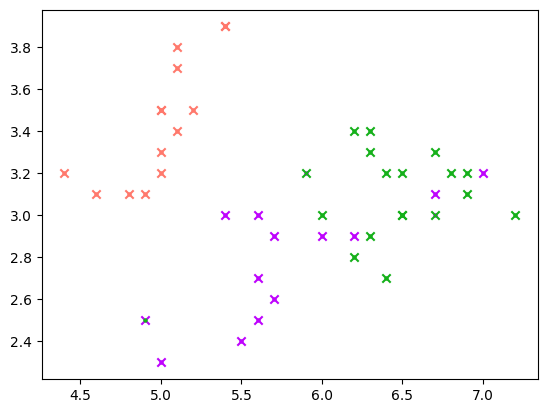

In [12]:
colors = np.array(['xkcd:salmon', 'xkcd:bright purple','xkcd:green' ])

print('tarin acc:', np.mean(y_train_pred.ravel() == y_train.ravel()) * 100)
print('predicted acc:', np.mean(y_pred.ravel() == y_test.ravel()) * 100)

for n, color in enumerate(colors) :  
    data2 = X_test[y_pred == n]
    plt.scatter(data2[:, 0], data2[:, 1], color=color, marker="x")

    data = X_test[y_test == n]
    plt.scatter(data[:, 0], data[:, 1], color=color, s=5)

## EM -алгоритм / GaussianMixture

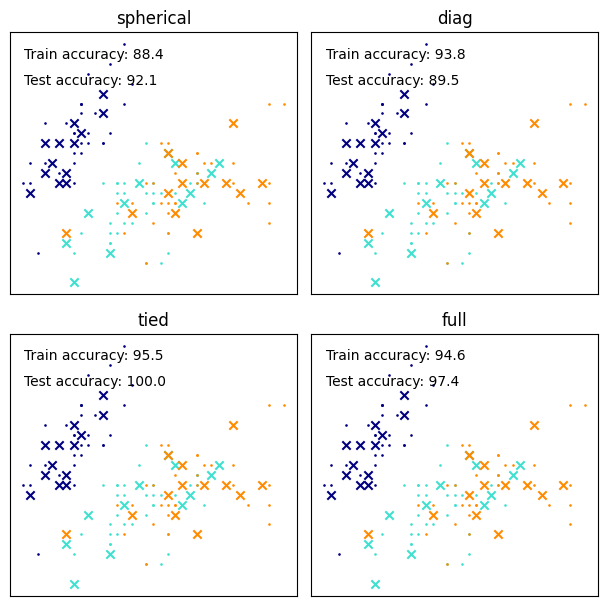

In [14]:
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import StratifiedKFold

colors = ["navy", "turquoise", "darkorange"]

iris = datasets.load_iris()


skf = StratifiedKFold(n_splits=4)

train_index, test_index = next(iter(skf.split(iris.data, iris.target)))


X_train = iris.data[train_index]
y_train = iris.target[train_index]
X_test = iris.data[test_index]
y_test = iris.target[test_index]

n_classes = len(np.unique(y_train))

estimators = {
    cov_type: GaussianMixture(
        n_components=n_classes, covariance_type=cov_type, max_iter=20, random_state=0
    )
    for cov_type in ["spherical", "diag", "tied", "full"]
}

n_estimators = len(estimators)

plt.figure(figsize=(3 * n_estimators // 2, 6))
plt.subplots_adjust(
    bottom=0.01, top=0.95, hspace=0.15, wspace=0.05, left=0.01, right=0.99
)


for index, (name, estimator) in enumerate(estimators.items()):
    estimator.means_init = np.array(
        [X_train[y_train == i].mean(axis=0) for i in range(n_classes)]
    )

    estimator.fit(X_train)

    h = plt.subplot(2, n_estimators // 2, index + 1)

    for n, color in enumerate(colors):
        data = iris.data[iris.target == n]
        plt.scatter(
            data[:, 0], data[:, 1], s=0.8, color=color, label=iris.target_names[n]
        )
    for n, color in enumerate(colors):
        data = X_test[y_test == n]
        plt.scatter(data[:, 0], data[:, 1], marker="x", color=color)

    y_train_pred = estimator.predict(X_train)
    train_accuracy = np.mean(y_train_pred.ravel() == y_train.ravel()) * 100
    plt.text(0.05, 0.9, "Train accuracy: %.1f" % train_accuracy, transform=h.transAxes)

    y_test_pred = estimator.predict(X_test)
    test_accuracy = np.mean(y_test_pred.ravel() == y_test.ravel()) * 100
    plt.text(0.05, 0.8, "Test accuracy: %.1f" % test_accuracy, transform=h.transAxes)

    plt.xticks(())
    plt.yticks(())
    plt.title(name)

#plt.legend(scatterpoints=1, loc="lower right", prop=dict(size=12))
